# Lab 7 — Go-to-goal: planned vs model vs real

Digits **9** and **1** (last two digits of the student ID) as 8 waypoints. The same block program
(`go_to_goal_sim.qrs` / `go_to_goal_real.qrs`; only `r`, `B` and the log name differ) estimates its
pose with the Lab 6 odometry and drives to one waypoint after another. It logs `x,y,time` (cm, cm, ms).

| Quantity | In the program |
|---|---|
| distance, bearing | `ρ = √(dx² + dy²)`, `θ_g = atan2(dy, dx)` |
| heading error (wrapped) | `e = atan2(sin(θ_g − θ), cos(θ_g − θ))` |
| linear (motor %) | `v = clamp(K_v·ρ, 25, 50) · max(0, cos e)³` |
| angular (motor %) | `ω = clamp(K_θ·e, −40, 40)` |
| wheels | `pL = v − ω`, `pR = v + ω` (M4 = left, M3 = right) |
| switch waypoint | `ρ < ε` |

Gains: `K_v = 200 %/m`, `K_θ = 100 %/rad`, `ε = 0.03 m`. The `cos(e)³` factor makes the robot turn
almost in place when the next waypoint is far to the side, and drive while turning when it is nearly ahead.

In [1]:
import os
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization

try:                                # in Colab: upload both txt files
    from google.colab import files  # file work module
    uploaded = files.upload()       # select BOTH txt files
except ImportError:                 # local Jupyter: files next to the notebook
    pass

# Planned waypoints, cm: copied from the init block (wx, wy are in m there)
wp = np.array([[0, 0], [0, 60], [-30, 60], [-30, 30], [0, 30], [30, 0], [30, 60], [21.5, 51.5]])

x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt', delimiter=',', unpack=True)
have_real = os.path.exists('odometry_data_real.txt')
if have_real:
    x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)

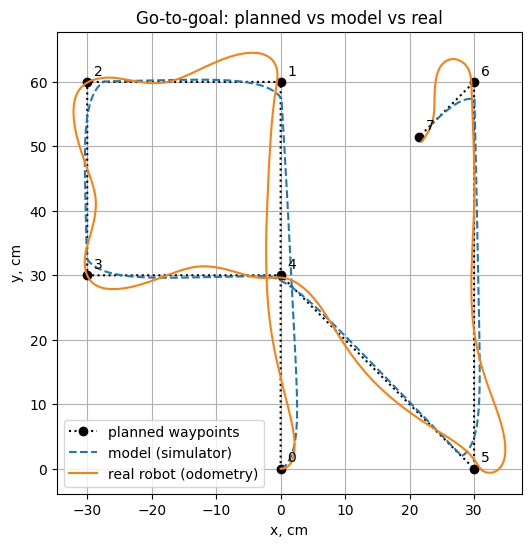

In [2]:
# 1. Planned path vs simulated vs real
plt.figure(figsize=(6, 6))
plt.plot(wp[:, 0], wp[:, 1], 'k:o', label='planned waypoints')
plt.plot(x_s, y_s, '--', label='model (simulator)')
if have_real:
    plt.plot(x_r, y_r, label='real robot (odometry)')
for i, (px, py) in enumerate(wp):
    plt.annotate(str(i), (px, py), textcoords='offset points', xytext=(5, 5))
plt.axis('equal'); plt.grid(True); plt.legend(loc='lower left')
plt.xlabel('x, cm'); plt.ylabel('y, cm')
plt.title('Go-to-goal: planned vs model vs real')
plt.show()

In [3]:
# 2. How close did each run get to each waypoint?
def waypoint_miss(x, y, wp):
    return np.array([np.min(np.hypot(x - px, y - py)) for px, py in wp])

miss_s = waypoint_miss(x_s, y_s, wp)
miss_r = waypoint_miss(x_r, y_r, wp) if have_real else np.full(len(wp), np.nan)
for i, (ms, mr) in enumerate(zip(miss_s, miss_r)):
    print(f'Waypoint {i} ({wp[i, 0]:g}, {wp[i, 1]:g}): sim {ms:5.1f} cm | real {mr:5.1f} cm')

# 3. Run time
real_t = f'{(t_r[-1] - t_r[0]) / 1000:.1f} s' if have_real else 'n/a'
print(f'Run time: sim {(t_s[-1] - t_s[0]) / 1000:.1f} s | real {real_t}')

Waypoint 0 (0, 0): sim   0.0 cm | real   0.0 cm
Waypoint 1 (0, 60): sim   1.8 cm | real   0.6 cm
Waypoint 2 (-30, 60): sim   1.8 cm | real   0.2 cm
Waypoint 3 (-30, 30): sim   1.8 cm | real   0.2 cm
Waypoint 4 (0, 30): sim   0.7 cm | real   0.4 cm
Waypoint 5 (30, 0): sim   2.7 cm | real   0.8 cm
Waypoint 6 (30, 60): sim   2.7 cm | real   0.5 cm
Waypoint 7 (21.5, 51.5): sim   2.7 cm | real   0.8 cm
Run time: sim 30.9 s | real 17.4 s


## How far off the straight lines?

The miss table only looks at the corners. This also measures how far each run strays from the
planned segments (the bowing between corners).

In [4]:
def off_path(x, y, wp):
    p = np.stack([x, y], 1)
    best = np.full(len(p), np.inf)
    for a, b in zip(wp[:-1], wp[1:]):
        ab = b - a
        s = np.clip((p - a) @ ab / (ab @ ab), 0, 1)
        best = np.minimum(best, np.hypot(*(p - (a + s[:, None] * ab)).T))
    return best

print(f'max distance from the planned path: sim {off_path(x_s, y_s, wp).max():.1f} cm', end='')
print(f' | real {off_path(x_r, y_r, wp).max():.1f} cm' if have_real else '')

max distance from the planned path: sim 2.6 cm | real 5.4 cm


## Measured end point (tape)

Measure the axle midpoint after the run in the start frame (x = start direction, y = to the left).

In [5]:
x_meas, y_meas = 6.0, 26.0          # cm, tape (6 cm forward, 26 cm to the left of the start mark)
h_meas = -80.0                      # deg, final heading: about 80 deg to the right of the start direction

last_wp = wp[-1]
print(f'last waypoint:         ({last_wp[0]:6.1f}, {last_wp[1]:6.1f}) cm')
print(f'sim, last log line:    ({x_s[-1]:6.1f}, {y_s[-1]:6.1f}) cm')
if have_real:
    print(f'real, last log line:   ({x_r[-1]:6.1f}, {y_r[-1]:6.1f}) cm')
    print(f'real, tape:            ({x_meas:6.1f}, {y_meas:6.1f}) cm')
    print(f'tape vs last waypoint: {np.hypot(x_meas - last_wp[0], y_meas - last_wp[1]):.1f} cm  (control + localization)')
    print(f'tape vs odometry:      {np.hypot(x_meas - x_r[-1], y_meas - y_r[-1]):.1f} cm  (localization only)')
    # odometry heading from the last moving step of the log
    dxr, dyr = np.diff(x_r), np.diff(y_r)
    m = np.hypot(dxr, dyr) > 1e-6
    h_odo = np.degrees(np.arctan2(dyr[m][-1], dxr[m][-1]))
    print(f'heading: odometry {h_odo:.0f} deg | tape {h_meas:.0f} deg | '
          f'difference {(h_meas - h_odo + 180) % 360 - 180:.0f} deg')

last waypoint:         (  21.5,   51.5) cm
sim, last log line:    (  23.4,   53.4) cm
real, last log line:   (  21.9,   50.7) cm
real, tape:            (   6.0,   26.0) cm
tape vs last waypoint: 29.8 cm  (control + localization)
tape vs odometry:      29.4 cm  (localization only)
heading: odometry -128 deg | tape -80 deg | difference 48 deg


## Discussion

No corner was cut. `ε = 3 cm` switches waypoints late, and `K_θ = 100` with the `cos(e)³` speed factor
turns almost in place, so both runs passed every waypoint within 2.7 cm (in tuning, `ε = 5 cm` and `K_θ = 60`
rounded corners by 4.7 cm). The real robot instead **overshot** every 90°/135° corner by 2–4.5 cm (simulator ≤ 0.4 cm; worst
at corner 1, at the end of the longest leg) and weaved up to 5.4 cm off the lines, because `K_θ = 100` meets a 57 ms control loop and 0.16 s motor lag, while the
simulator ran at 20 ms. The tape shows a much bigger error: the robot stopped at (6, 26) cm facing about 80°
right, while its odometry believed (21.9, 50.7) cm facing −128°, i.e. 29 cm and 48° off. Since the
controller tracked its own estimate within 1 cm, the remaining real-vs-model gap is a **localization**
problem: 48° over 592° of turning is about 8 %, pointing at the unmeasured wheel base `B = 0.194` m
(≈ 0.18 m would fit) plus wheel slip in the fast in-place turns.